In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

import shap
from lime.lime_tabular import LimeTabularExplainer

out_dir = "xai_outputs_ckd"
os.makedirs(out_dir, exist_ok=True)

# =========================
# 1. LOAD + BASIC CLEANING
# =========================
file_path = "../../data/ckd/kidney_disease.csv"
df = pd.read_csv(file_path)

df = df.replace(r'^\s+|\s+$', '', regex=True)
df = df.replace('?', np.nan)
df = df.replace('\t?', np.nan)
df = df.replace({'\tyes': 'yes', '\tno': 'no', ' yes': 'yes', ' no': 'no'})

possible_targets = ['classification', 'class', 'target', 'label']
target_col = next((c for c in possible_targets if c in df.columns), None)
if target_col is None:
    raise ValueError("Target column not found.")

df[target_col] = df[target_col].astype(str).str.strip().str.lower()
df[target_col] = df[target_col].replace({
    'ckd\t': 'ckd',
    'notckd': 'notckd',
    'not ckd': 'notckd'
})

df = df[df[target_col].isin(['ckd', 'notckd'])].copy()

X = df.drop(columns=[target_col]).copy()
y = df[target_col].map({'ckd': 1, 'notckd': 0})

if 'id' in X.columns:
    X = X.drop(columns=['id'])

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='ignore')

numeric_cols = X.select_dtypes(include=['number']).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

feature_names = X.columns.tolist()

print("Shape:", X.shape)
print("Target counts:\n", y.value_counts())
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

# =========================
# 2. SPLIT FIRST (NO-LEAKAGE)
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# =========================
# 3. IMPUTATION USING TRAIN ONLY
# =========================
rng = np.random.default_rng(42)

def random_sample_impute_train_test(train_s, test_s, rng_obj):
    train_s = train_s.copy()
    test_s = test_s.copy()

    observed = train_s.dropna().values
    if len(observed) == 0:
        return train_s, test_s

    train_missing = train_s.isna()
    if train_missing.sum() > 0:
        sampled_train = rng_obj.choice(observed, size=train_missing.sum(), replace=True)
        train_s.loc[train_missing] = sampled_train

    observed = train_s.dropna().values

    test_missing = test_s.isna()
    if test_missing.sum() > 0:
        sampled_test = rng_obj.choice(observed, size=test_missing.sum(), replace=True)
        test_s.loc[test_missing] = sampled_test

    return train_s, test_s

for col in numeric_cols:
    try:
        X_train[col], X_test[col] = random_sample_impute_train_test(X_train[col], X_test[col], rng)
    except Exception:
        mean_val = X_train[col].mean()
        X_train[col] = X_train[col].fillna(mean_val)
        X_test[col] = X_test[col].fillna(mean_val)

for col in categorical_cols:
    try:
        X_train[col], X_test[col] = random_sample_impute_train_test(X_train[col], X_test[col], rng)
    except Exception:
        mode_val = X_train[col].mode(dropna=True)
        if len(mode_val) > 0:
            fill_val = mode_val.iloc[0]
            X_train[col] = X_train[col].fillna(fill_val)
            X_test[col] = X_test[col].fillna(fill_val)

for col in numeric_cols:
    mean_val = X_train[col].mean()
    X_train[col] = X_train[col].fillna(mean_val)
    X_test[col] = X_test[col].fillna(mean_val)

for col in categorical_cols:
    mode_val = X_train[col].mode(dropna=True)
    if len(mode_val) > 0:
        fill_val = mode_val.iloc[0]
        X_train[col] = X_train[col].fillna(fill_val)
        X_test[col] = X_test[col].fillna(fill_val)

# =========================
# 4. LABEL ENCODING
# =========================
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    combined_vals = pd.concat([X_train[col], X_test[col]], axis=0).astype(str)
    le.fit(combined_vals)

    X_train[col] = le.transform(X_train[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    encoders[col] = le

# keeping copies for explainability
X_train_enc = X_train.copy()
X_test_enc = X_test.copy()

# =========================
# 5. FINAL EXPLAINED MODEL = RF
# =========================
final_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

final_model.fit(X_train_enc, y_train)

y_pred = final_model.predict(X_test_enc)
y_prob = final_model.predict_proba(X_test_enc)[:, 1]

print("Final XAI model: Random Forest (no-leakage pipeline)")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1       :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("AUC      :", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\catia\AppData\Local\Temp\ipykernel_3404\1152318432.py:56: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  X[col] = pd.to_numeric(X[col], errors='ignore')


Shape: (400, 24)
Target counts:
 classification
1    250
0    150
Name: count, dtype: int64
Numeric: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
Categorical: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
Final XAI model: Random Forest (no-leakage pipeline)
Accuracy : 0.9833
Precision: 0.9867
Recall   : 0.9867
F1       : 0.9867
AUC      : 0.9991

Confusion matrix:
[[44  1]
 [ 1 74]]



Permutation importance
   Feature  PermutationMean  PermutationStd
2       sg           0.1289          0.0279
11      sc           0.0078          0.0064
15     pcv           0.0064          0.0117
17      rc           0.0022          0.0037
21   appet           0.0017          0.0040
3       al           0.0014          0.0061
19      dm           0.0006          0.0052
1       bp           0.0000          0.0000
7      pcc           0.0000          0.0000
6       pc           0.0000          0.0000
5      rbc           0.0000          0.0000
4       su           0.0000          0.0000
0      age           0.0000          0.0000
13     pot           0.0000          0.0000
10      bu           0.0000          0.0000
8       ba           0.0000          0.0000
22      pe           0.0000          0.0000
20     cad           0.0000          0.0000
12     sod           0.0000          0.0000
16      wc           0.0000          0.0000
23     ane           0.0000          0.0000
18     h

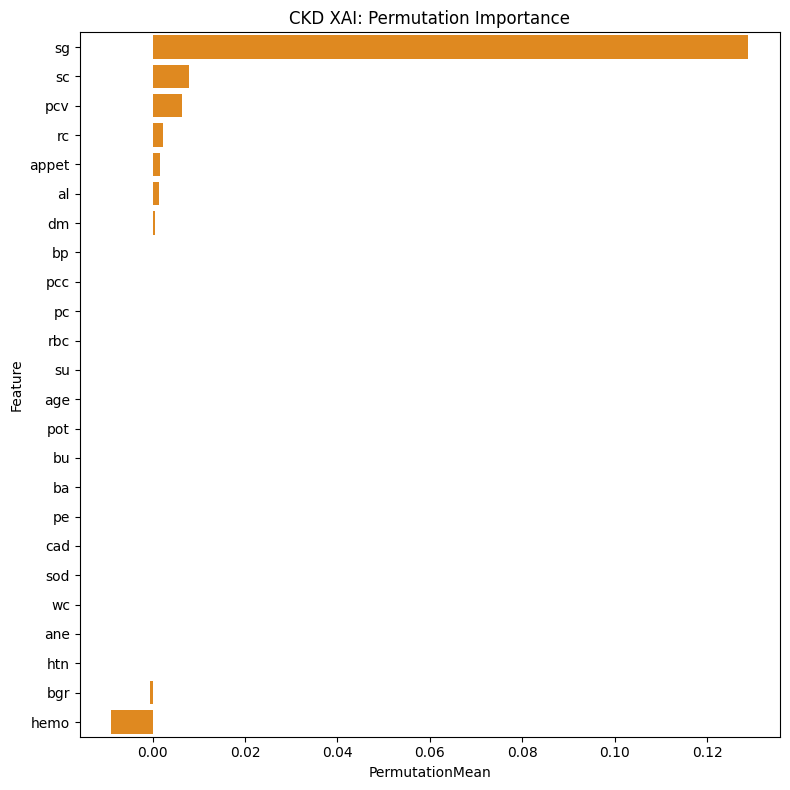

In [2]:
# =========================
# 6. GLOBAL XAI: PERMUTATION IMPORTANCE
# =========================
perm = permutation_importance(
    final_model,
    X_test_enc,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="accuracy"
)

perm_df = pd.DataFrame({
    "Feature": X_test_enc.columns,
    "PermutationMean": perm.importances_mean,
    "PermutationStd": perm.importances_std
}).sort_values("PermutationMean", ascending=False)

print("\nPermutation importance")
print(perm_df.round(4))

plt.figure(figsize=(8, 8))
sns.barplot(data=perm_df, x="PermutationMean", y="Feature", color="darkorange")
plt.title("CKD XAI: Permutation Importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ckd_permutation_importance.png"), dpi=300)
plt.show()


Final SHAP matrix shape: (120, 24)


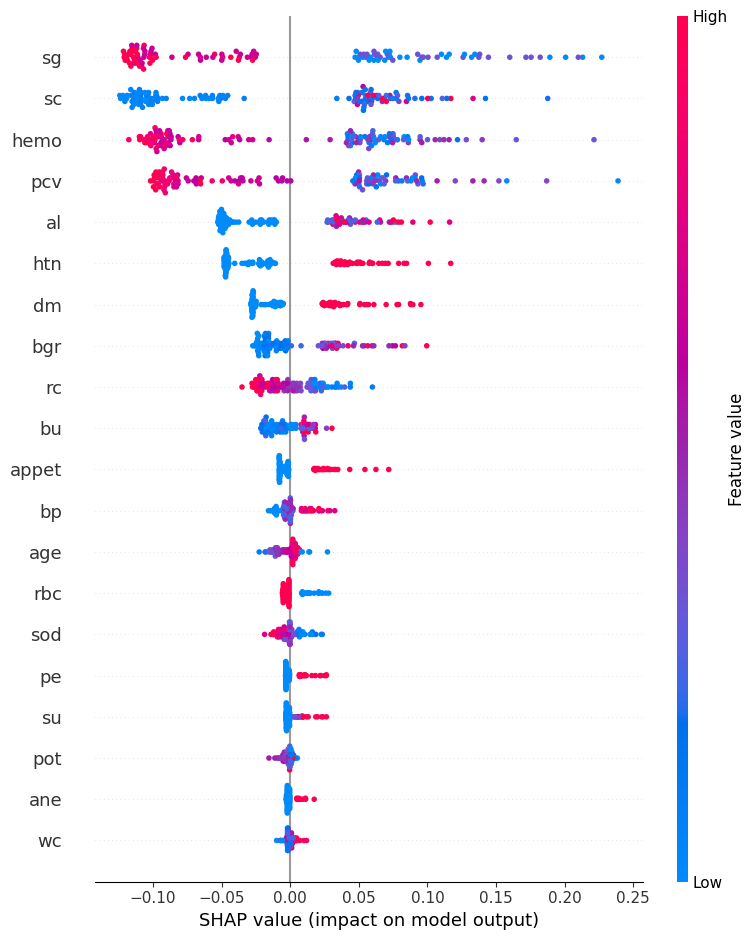

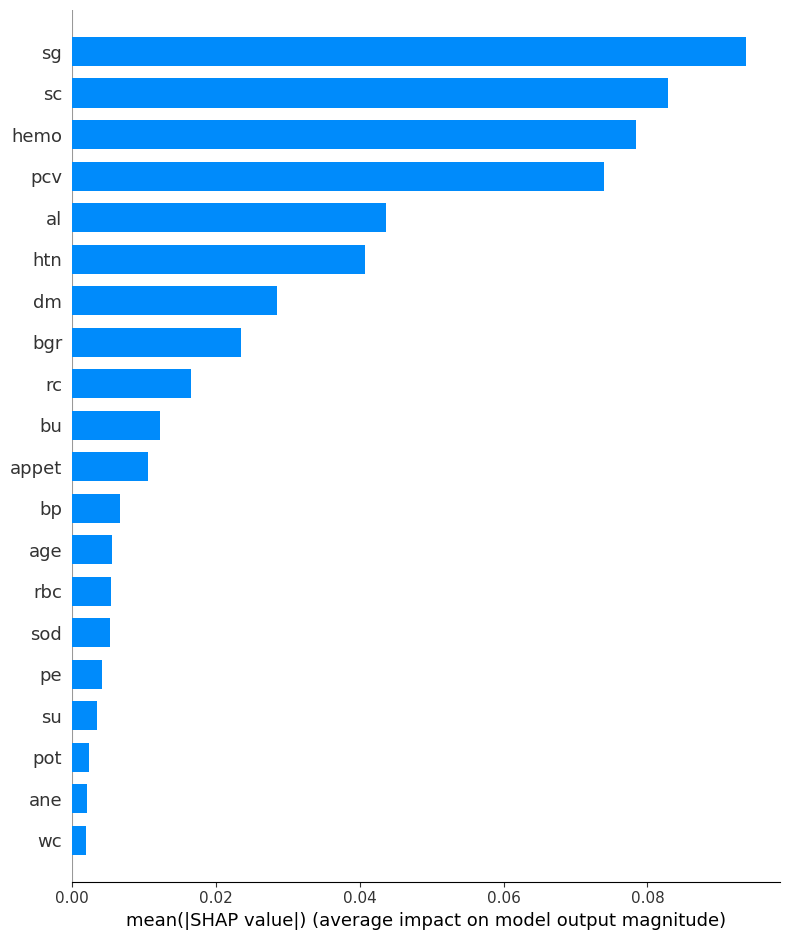


SHAP importance
   Feature  MeanAbsSHAP
2       sg       0.0937
11      sc       0.0829
14    hemo       0.0785
15     pcv       0.0740
3       al       0.0437
18     htn       0.0407
19      dm       0.0285
9      bgr       0.0235
17      rc       0.0166
10      bu       0.0122
21   appet       0.0106
1       bp       0.0066
0      age       0.0056
5      rbc       0.0054
12     sod       0.0054
22      pe       0.0042
4       su       0.0035
13     pot       0.0024
23     ane       0.0021
16      wc       0.0020
6       pc       0.0011
7      pcc       0.0002
8       ba       0.0001
20     cad       0.0001


In [3]:
# =========================
# 7. GLOBAL XAI: SHAP
# =========================
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_enc)

if isinstance(shap_values, list):
    shap_plot_values = shap_values[1]
    expected_value = explainer.expected_value[1]
else:
    shap_values = np.array(shap_values)

    if shap_values.ndim == 3:
        shap_plot_values = shap_values[:, :, 1]
        expected_value = (
            explainer.expected_value[1]
            if np.ndim(explainer.expected_value) > 0
            else explainer.expected_value
        )
    else:
        shap_plot_values = shap_values
        expected_value = explainer.expected_value

print("Final SHAP matrix shape:", np.array(shap_plot_values).shape)

shap.summary_plot(shap_plot_values, X_test_enc, show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ckd_shap_summary.png"), dpi=300, bbox_inches="tight")
plt.show()

shap.summary_plot(shap_plot_values, X_test_enc, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ckd_shap_bar.png"), dpi=300, bbox_inches="tight")
plt.show()

shap_imp = pd.DataFrame({
    "Feature": X_test_enc.columns,
    "MeanAbsSHAP": np.abs(shap_plot_values).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print("\nSHAP importance")
print(shap_imp.round(4))



SHAP vs permutation rank comparison
   Feature  MeanAbsSHAP  SHAPRank  PermutationMean  PermutationRank
0       sg       0.0937         1           0.1289                1
1       sc       0.0829         2           0.0078                2
2     hemo       0.0785         3          -0.0089               24
3      pcv       0.0740         4           0.0064                3
4       al       0.0437         5           0.0014                6
5      htn       0.0407         6          -0.0000               22
6       dm       0.0285         7           0.0006                7
7      bgr       0.0235         8          -0.0006               23
8       rc       0.0166         9           0.0022                4
9       bu       0.0122        10           0.0000               15
10   appet       0.0106        11           0.0017                5
11      bp       0.0066        12           0.0000                8
12     age       0.0056        13           0.0000               13
13     rbc 

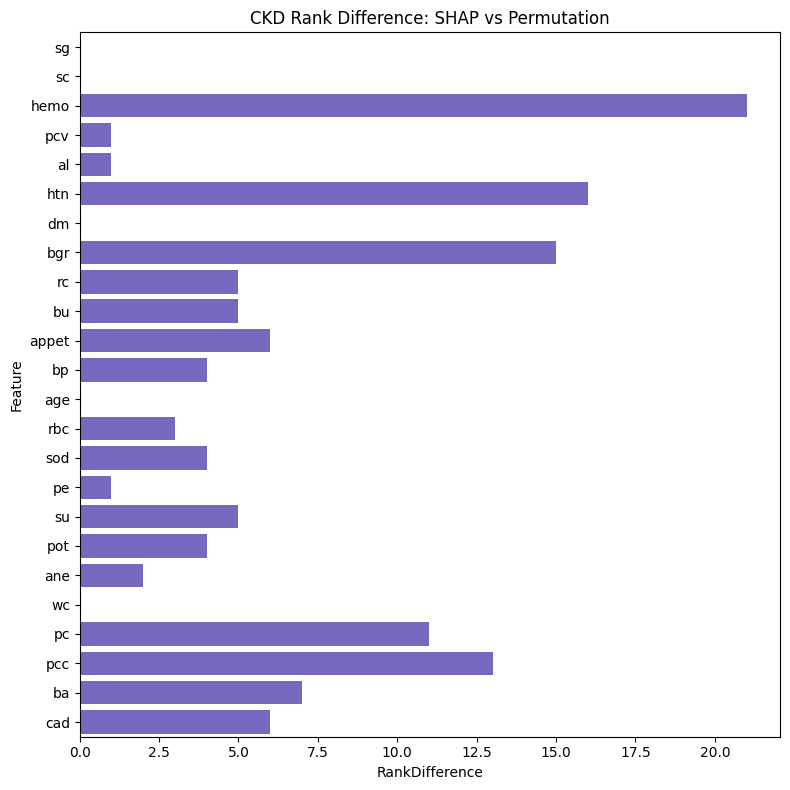

In [4]:
# =========================
# 8. SHAP vs PERMUTATION AGREEMENT
# =========================
perm_rank = perm_df[["Feature", "PermutationMean"]].reset_index(drop=True).copy()
perm_rank["PermutationRank"] = np.arange(1, len(perm_rank) + 1)

shap_rank = shap_imp[["Feature", "MeanAbsSHAP"]].reset_index(drop=True).copy()
shap_rank["SHAPRank"] = np.arange(1, len(shap_rank) + 1)

rank_compare = shap_rank.merge(
    perm_rank,
    on="Feature",
    how="left"
)

from scipy.stats import spearmanr, kendalltau

rho, rho_p = spearmanr(rank_compare["SHAPRank"], rank_compare["PermutationRank"])
tau, tau_p = kendalltau(rank_compare["SHAPRank"], rank_compare["PermutationRank"])

print("\nSHAP vs permutation rank comparison")
print(rank_compare.round(4))
print(f"\nSpearman rank correlation: {rho:.4f} (p={rho_p:.4f})")
print(f"Kendall tau: {tau:.4f} (p={tau_p:.4f})")

rank_compare["RankDifference"] = (
    rank_compare["SHAPRank"] - rank_compare["PermutationRank"]
).abs()

plt.figure(figsize=(8, 8))
sns.barplot(
    data=rank_compare.sort_values("SHAPRank"),
    x="RankDifference",
    y="Feature",
    color="slateblue"
)
plt.title("CKD Rank Difference: SHAP vs Permutation")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ckd_rank_difference_shap_vs_perm.png"), dpi=300)
plt.show()



Top 3 SHAP features: ['sg', 'sc', 'hemo']


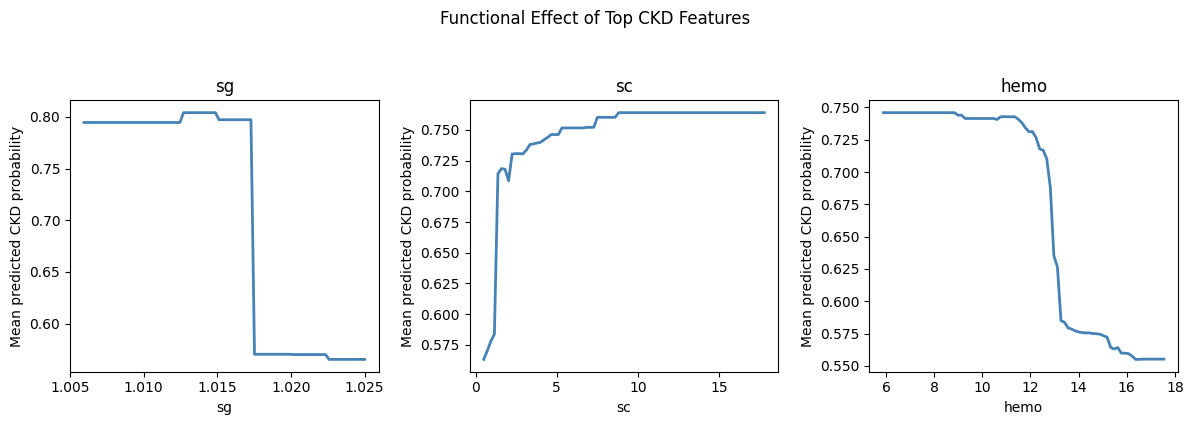

In [5]:
# =========================
# 9. FUNCTIONAL XAI: FEATURE EFFECT PROFILES
# =========================
top_features = shap_imp["Feature"].head(3).tolist()
print("\nTop 3 SHAP features:", top_features)

fig, axes = plt.subplots(1, len(top_features), figsize=(12, 4))

if len(top_features) == 1:
    axes = [axes]

X_ref = X_test_enc.copy()

for ax, feat in zip(axes, top_features):
    grid = np.linspace(
        X_ref[feat].quantile(0.01),
        X_ref[feat].quantile(0.99),
        80
    )

    mean_probs = []

    for val in grid:
        X_temp = X_ref.copy()
        X_temp[feat] = val
        probs = final_model.predict_proba(X_temp)[:, 1]
        mean_probs.append(probs.mean())

    ax.plot(grid, mean_probs, color="steelblue", linewidth=2)
    ax.set_title(feat)
    ax.set_xlabel(feat)
    ax.set_ylabel("Mean predicted CKD probability")

fig.suptitle("Functional Effect of Top CKD Features", y=1.05)
plt.tight_layout()
fig.savefig(os.path.join(out_dir, "ckd_functional_profiles_top3.png"), dpi=300, bbox_inches="tight")
plt.show()


In [6]:
# =========================
# 10. LOCAL XAI: REPRESENTATIVE CASES
# =========================
case_df = X_test_enc.copy()
case_df["y_true"] = y_test.values
case_df["y_pred"] = y_pred
case_df["y_prob"] = y_prob
case_df["dist_to_05"] = np.abs(case_df["y_prob"] - 0.5)

tp = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

tn = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

fp = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

fn = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

borderline = case_df.sort_values("dist_to_05").head(1).copy()

tp["CaseType"] = "TP"
tn["CaseType"] = "TN"
fp["CaseType"] = "FP"
fn["CaseType"] = "FN"
borderline["CaseType"] = "Borderline"

rep_cases = pd.concat([tp, tn, fp, fn, borderline]).drop_duplicates()

print("\nRepresentative cases")
print(rep_cases.round(4))

rep_indices = rep_cases.index.tolist()

rep_cases.to_csv(
    os.path.join(out_dir, "ckd_representative_cases.csv"),
    index=True
)



Representative cases
      age    bp     sg   al   su  rbc  pc  pcc  ba    bgr  ...  dm  cad  \
127  71.0  60.0  1.015  4.0  0.0    1   1    0   0  118.0  ...   1    0   
356  34.0  70.0  1.025  0.0  0.0    1   1    0   0   87.0  ...   0    0   
324  40.0  80.0  1.020  0.0  0.0    1   1    0   0  119.0  ...   0    0   
224  34.0  60.0  1.020  0.0  0.0    1   1    0   0  117.0  ...   0    0   
224  34.0  60.0  1.020  0.0  0.0    1   1    0   0  117.0  ...   0    0   

     appet  pe  ane  y_true  y_pred  y_prob  dist_to_05    CaseType  
127      1   1    0       1       1    1.00        0.50          TP  
356      0   0    0       0       0    0.00        0.50          TN  
324      0   0    0       0       1    0.69        0.19          FP  
224      0   1    0       1       0    0.40        0.10          FN  
224      0   1    0       1       0    0.40        0.10  Borderline  

[5 rows x 29 columns]



SHAP local explanation for case 127
CaseType     TP
y_true        1
y_pred        1
y_prob      1.0
Name: 127, dtype: object


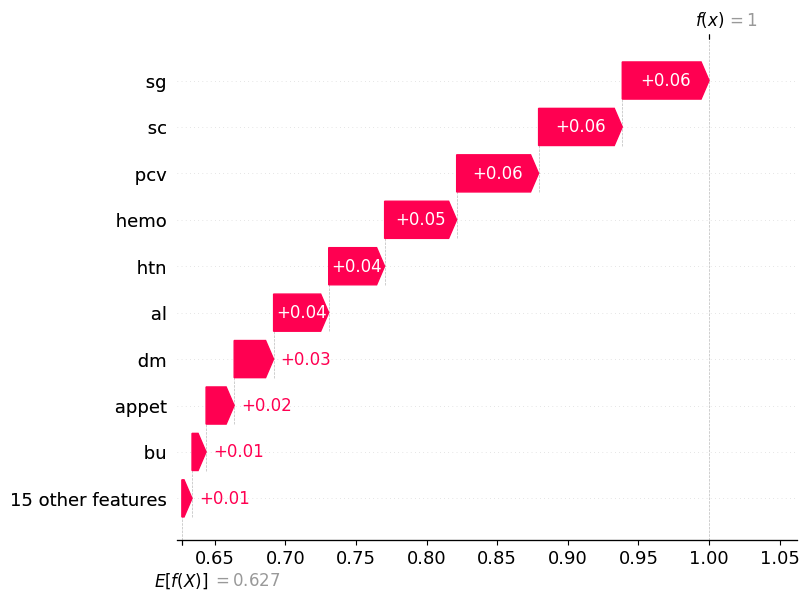

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 356
CaseType     TN
y_true        0
y_pred        0
y_prob      0.0
Name: 356, dtype: object


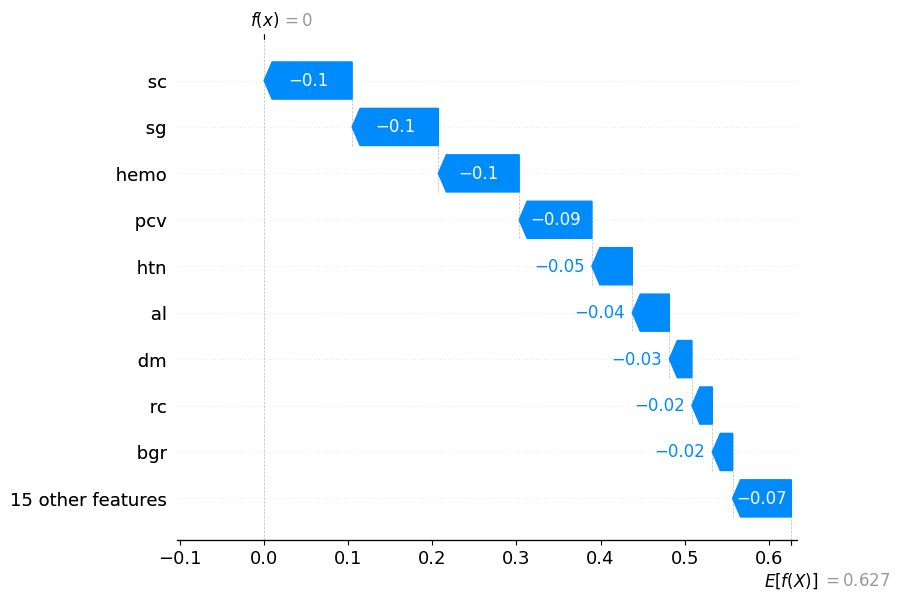

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 324
CaseType      FP
y_true         0
y_pred         1
y_prob      0.69
Name: 324, dtype: object


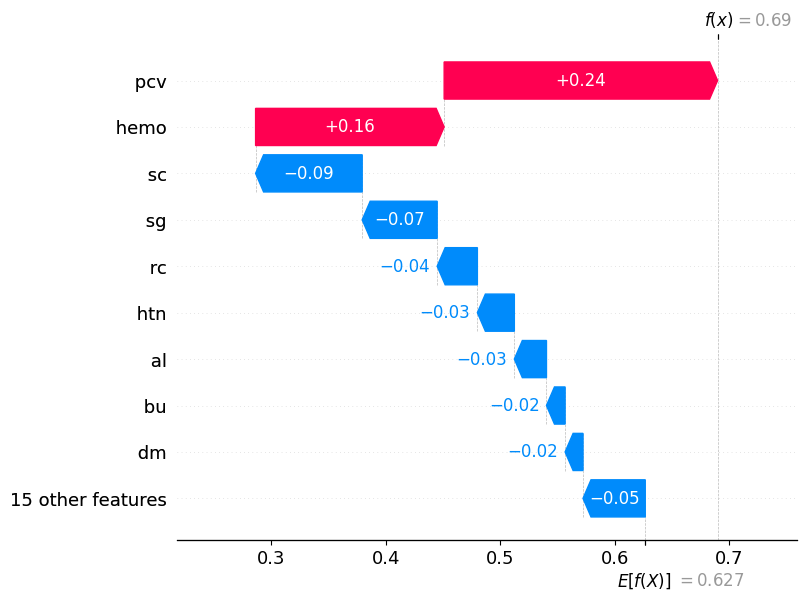

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 224
       CaseType  y_true  y_pred  y_prob
224          FN       1       0     0.4
224  Borderline       1       0     0.4


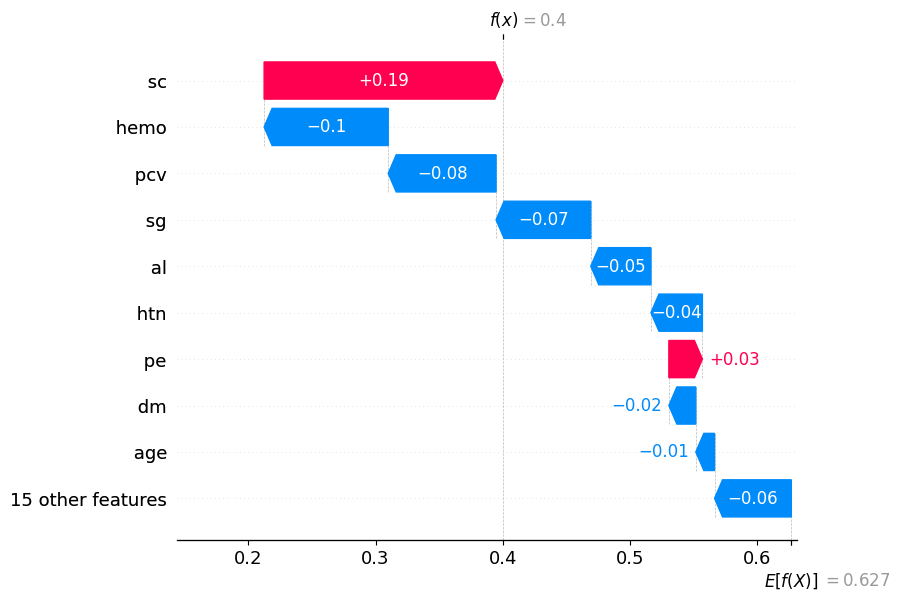

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 224
       CaseType  y_true  y_pred  y_prob
224          FN       1       0     0.4
224  Borderline       1       0     0.4


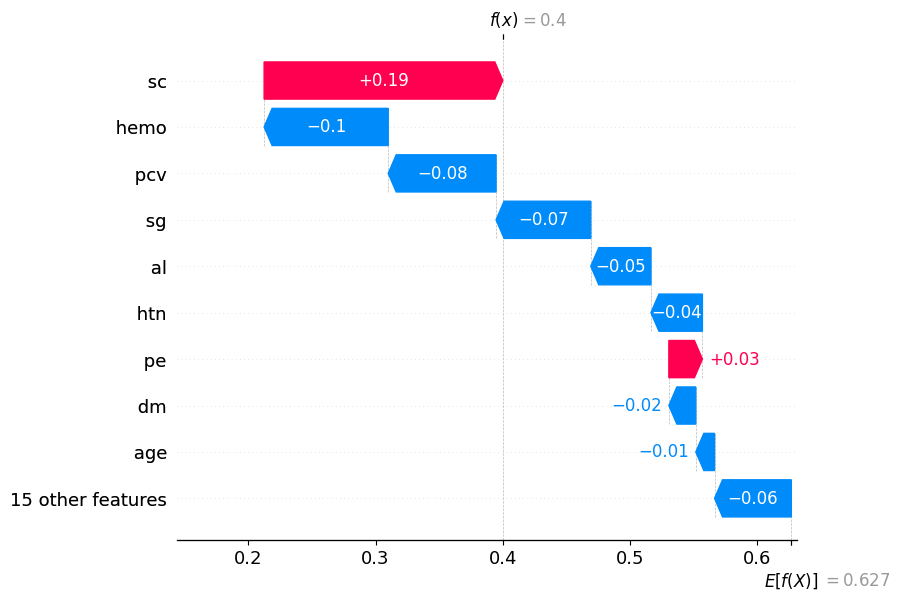

<Figure size 640x480 with 0 Axes>

In [7]:
# =========================
# 11. SHAP LOCAL EXPLANATIONS
# =========================
for idx in rep_indices:
    row = X_test_enc.loc[[idx]]

    shap_single = explainer.shap_values(row)

    if isinstance(shap_single, list):
        shap_single_plot = shap_single[1]
        local_expected = explainer.expected_value[1]
    else:
        shap_single = np.array(shap_single)

        if shap_single.ndim == 3:
            shap_single_plot = shap_single[:, :, 1]
            local_expected = (
                explainer.expected_value[1]
                if np.ndim(explainer.expected_value) > 0
                else explainer.expected_value
            )
        else:
            shap_single_plot = shap_single
            local_expected = explainer.expected_value

    print(f"\nSHAP local explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])

    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        local_expected,
        shap_single_plot[0],
        feature_names=row.columns.tolist(),
        features=row.iloc[0].values
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"ckd_shap_waterfall_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 127
CaseType     TP
y_true        1
y_pred        1
y_prob      1.0
Name: 127, dtype: object
[('sc > 3.20', 0.0709276388783265), ('0.00 < htn <= 1.00', 0.06912117882923421), ('10.30 < hemo <= 12.70', 0.0677946862986395), ('0.00 < dm <= 1.00', 0.047883951795265334), ('32.00 < pcv <= 41.00', 0.047686733926005295), ('al > 2.00', 0.04377316773880477), ('appet > 0.00', 0.04090022970474124), ('bp <= 70.00', -0.014490206243702506), ('su <= 0.00', -0.011080671340172321), ('bu > 71.25', 0.010990493655192434)]


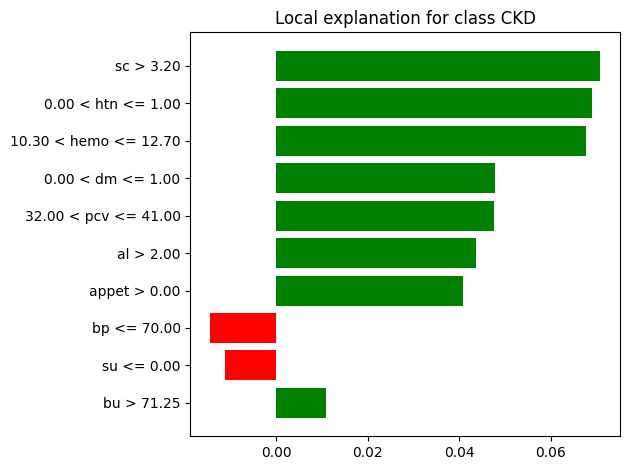

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 356
CaseType     TN
y_true        0
y_pred        0
y_prob      0.0
Name: 356, dtype: object
[('hemo > 15.00', -0.09744610989701152), ('sg > 1.02', -0.09664035678629371), ('pcv > 45.00', -0.09248851774634682), ('sc <= 0.97', -0.08584197465886742), ('htn <= 0.00', -0.06847621106349297), ('al <= 0.00', -0.05414377981488945), ('dm <= 0.00', -0.0442785482876208), ('bgr <= 99.00', -0.030845598674783342), ('appet <= 0.00', -0.029955991859378934), ('rc > 5.50', -0.019942229766094208)]


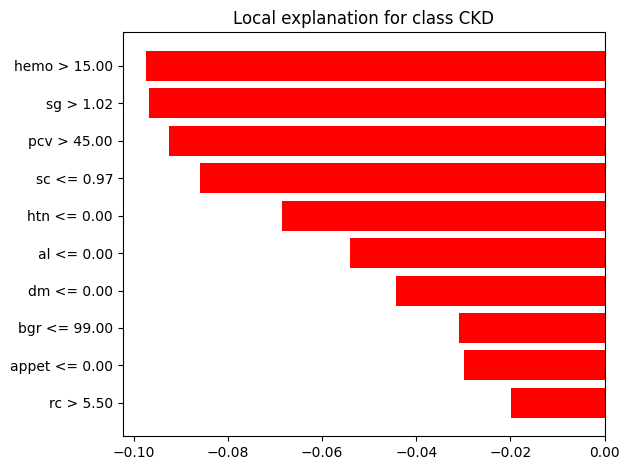

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 324
CaseType      FP
y_true         0
y_pred         1
y_prob      0.69
Name: 324, dtype: object
[('sc <= 0.97', -0.08435507129275704), ('pcv <= 32.00', 0.07513798351823275), ('htn <= 0.00', -0.07155090460295002), ('10.30 < hemo <= 12.70', 0.06712304803303203), ('al <= 0.00', -0.05551104035410487), ('dm <= 0.00', -0.041399181113166386), ('appet <= 0.00', -0.03238040888463151), ('age <= 43.00', -0.02240064933481927), ('sod > 142.00', -0.020759630183307447), ('rc > 5.50', -0.017650750999749706)]


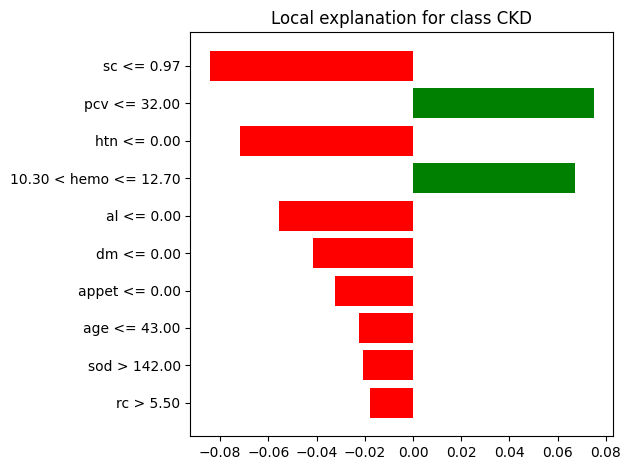

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 224
       CaseType  y_true  y_pred  y_prob
224          FN       1       0     0.4
224  Borderline       1       0     0.4
[('hemo > 15.00', -0.0959982914196261), ('htn <= 0.00', -0.07225986485537102), ('41.00 < pcv <= 45.00', -0.06381469140698864), ('al <= 0.00', -0.05376375742651684), ('1.35 < sc <= 3.20', 0.04704787455645436), ('dm <= 0.00', -0.046972584964868024), ('appet <= 0.00', -0.029863685660638843), ('age <= 43.00', -0.022105133041073272), ('bp <= 70.00', -0.01869380274031874), ('su <= 0.00', -0.014206411005940167)]


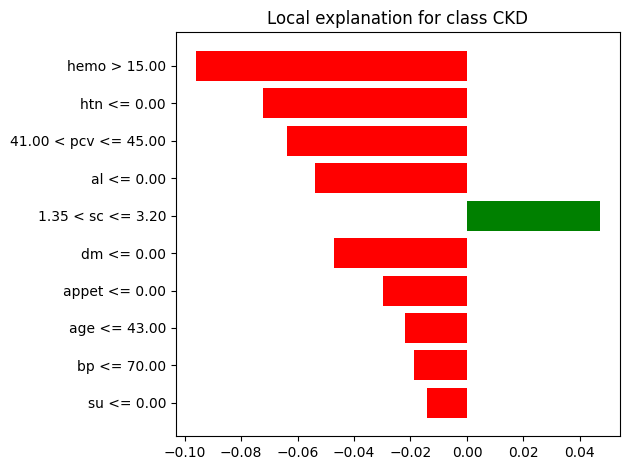

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



LIME explanation for case 224
       CaseType  y_true  y_pred  y_prob
224          FN       1       0     0.4
224  Borderline       1       0     0.4
[('hemo > 15.00', -0.10278073741202388), ('htn <= 0.00', -0.07281416749300058), ('41.00 < pcv <= 45.00', -0.06090548056668808), ('al <= 0.00', -0.05403611008395451), ('1.35 < sc <= 3.20', 0.05301920524618595), ('dm <= 0.00', -0.0429052617820071), ('appet <= 0.00', -0.038169519181080636), ('age <= 43.00', -0.02112733238204548), ('pe > 0.00', 0.0185731589734052), ('4.80 < rc <= 5.50', -0.01502334959242194)]


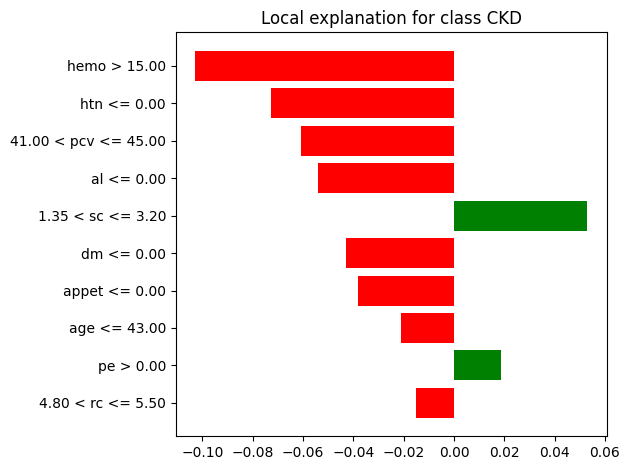

In [8]:
# =========================
# 12. LIME LOCAL EXPLANATIONS
# =========================
lime_explainer = LimeTabularExplainer(
    training_data=X_train_enc.values,
    feature_names=X_train_enc.columns.tolist(),
    class_names=["No CKD", "CKD"],
    mode="classification"
)

lime_rows = []

for idx in rep_indices:
    exp = lime_explainer.explain_instance(
        X_test_enc.loc[idx].values,
        final_model.predict_proba,
        num_features=min(10, X_test_enc.shape[1])
    )

    print(f"\nLIME explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])
    print(exp.as_list())

    for feat, weight in exp.as_list():
        lime_rows.append({
            "CaseIndex": idx,
            "CaseType": rep_cases.loc[idx, "CaseType"],
            "Rule": feat,
            "Weight": weight
        })

    fig = exp.as_pyplot_figure()
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"ckd_lime_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

lime_df = pd.DataFrame(lime_rows)


C:\Users\catia\AppData\Local\Temp\ipykernel_3404\90418663.py:15: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  X_seed[col] = pd.to_numeric(X_seed[col], errors='ignore')
C:\Users\catia\AppData\Local\Temp\ipykernel_3404\90418663.py:15: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  X_seed[col] = pd.to_numeric(X_seed[col], errors='ignore')
C:\Users\catia\AppData\Local\Temp\ipykernel_3404\90418663.py:15: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  X_seed[col] = pd.to_numeric(X_seed[col], errors='ignore')
C:\Users\catia\AppData\Local\Temp\ipykernel_3404\90418663.py:15: FutureWarning: errors='ignore' is deprecated and will raise in a future versi


Stability summary
         MeanImportance  StdImportance  MeanRank  StdRank
Feature                                                  
sg               0.1415         0.0194       1.0   0.0000
al               0.0298         0.0248       3.8   2.4900
sc               0.0288         0.0255       3.8   1.9235
hemo             0.0080         0.0063       4.6   1.1402
pcv              0.0550         0.0632       6.4   8.2037
appet            0.0022         0.0023       8.4   3.4351
bgr              0.0027         0.0036       9.2   5.3572
pe               0.0022         0.0025       9.4   4.6152
htn              0.0033         0.0044      10.2   4.6583
wc               0.0005         0.0011      10.2   5.0695
pcc              0.0002         0.0004      11.0   4.7434
ane              0.0000         0.0000      11.6   4.9295
su               0.0002         0.0007      11.6   4.1593
cad              0.0000         0.0000      11.6   4.9295
ba               0.0000         0.0000      11.6   4.

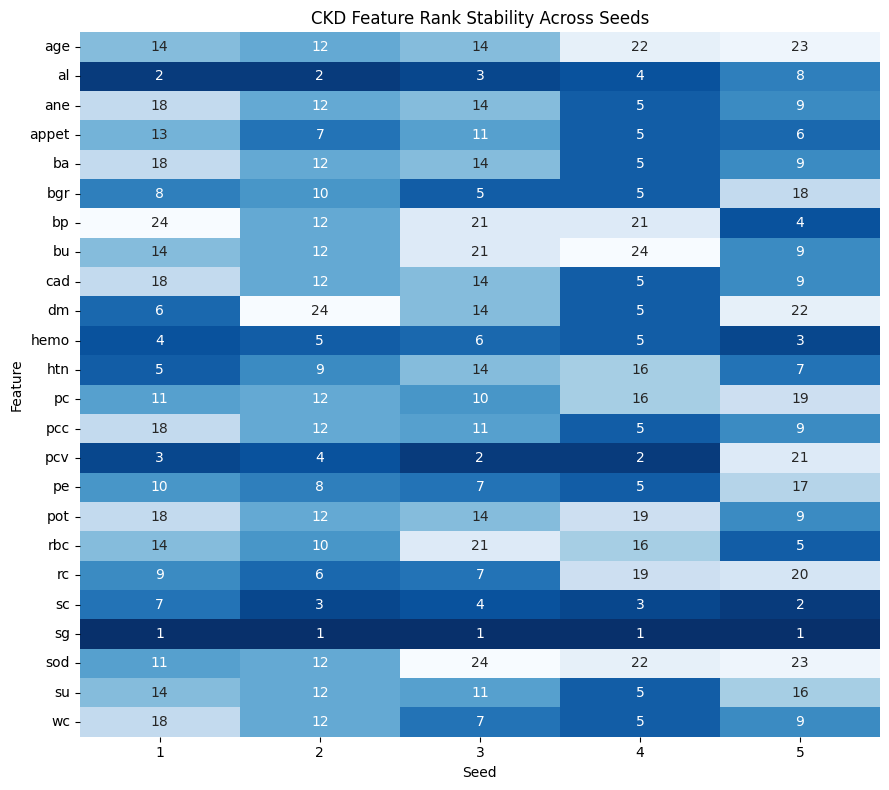

In [9]:
# =========================
# 13. STABILITY ANALYSIS ACROSS SEEDS
# =========================
seeds = [1, 2, 3, 4, 5]
stability_rows = []

for seed in seeds:
    X_seed = df.drop(columns=[target_col]).copy()
    y_seed = df[target_col].map({'ckd': 1, 'notckd': 0})

    if 'id' in X_seed.columns:
        X_seed = X_seed.drop(columns=['id'])

    for col in X_seed.columns:
        X_seed[col] = pd.to_numeric(X_seed[col], errors='ignore')

    numeric_cols_seed = X_seed.select_dtypes(include=['number']).columns.tolist()
    categorical_cols_seed = [c for c in X_seed.columns if c not in numeric_cols_seed]

    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_seed, y_seed,
        test_size=0.30,
        random_state=seed,
        stratify=y_seed
    )

    rng_s = np.random.default_rng(seed)

    for col in numeric_cols_seed:
        try:
            X_train_s[col], X_test_s[col] = random_sample_impute_train_test(X_train_s[col], X_test_s[col], rng_s)
        except Exception:
            mean_val = X_train_s[col].mean()
            X_train_s[col] = X_train_s[col].fillna(mean_val)
            X_test_s[col] = X_test_s[col].fillna(mean_val)

    for col in categorical_cols_seed:
        try:
            X_train_s[col], X_test_s[col] = random_sample_impute_train_test(X_train_s[col], X_test_s[col], rng_s)
        except Exception:
            mode_val = X_train_s[col].mode(dropna=True)
            if len(mode_val) > 0:
                fill_val = mode_val.iloc[0]
                X_train_s[col] = X_train_s[col].fillna(fill_val)
                X_test_s[col] = X_test_s[col].fillna(fill_val)

    for col in numeric_cols_seed:
        mean_val = X_train_s[col].mean()
        X_train_s[col] = X_train_s[col].fillna(mean_val)
        X_test_s[col] = X_test_s[col].fillna(mean_val)

    for col in categorical_cols_seed:
        mode_val = X_train_s[col].mode(dropna=True)
        if len(mode_val) > 0:
            fill_val = mode_val.iloc[0]
            X_train_s[col] = X_train_s[col].fillna(fill_val)
            X_test_s[col] = X_test_s[col].fillna(fill_val)

    for col in categorical_cols_seed:
        le = LabelEncoder()
        combined_vals = pd.concat([X_train_s[col], X_test_s[col]], axis=0).astype(str)
        le.fit(combined_vals)
        X_train_s[col] = le.transform(X_train_s[col].astype(str))
        X_test_s[col] = le.transform(X_test_s[col].astype(str))

    model_s = RandomForestClassifier(
        n_estimators=200,
        random_state=seed
    )

    model_s.fit(X_train_s, y_train_s)

    perm_s = permutation_importance(
        model_s,
        X_test_s,
        y_test_s,
        n_repeats=10,
        random_state=seed,
        scoring="accuracy"
    )

    temp = pd.DataFrame({
        "Feature": X_test_s.columns,
        "Importance": perm_s.importances_mean,
        "Seed": seed
    })

    stability_rows.append(temp)

stability_df = pd.concat(stability_rows, ignore_index=True)

stability_df["Rank"] = stability_df.groupby("Seed")["Importance"].rank(
    ascending=False,
    method="min"
)

stability_summary = stability_df.groupby("Feature").agg(
    MeanImportance=("Importance", "mean"),
    StdImportance=("Importance", "std"),
    MeanRank=("Rank", "mean"),
    StdRank=("Rank", "std")
).sort_values("MeanRank")

print("\nStability summary")
print(stability_summary.round(4))

rank_pivot = stability_df.pivot(index="Feature", columns="Seed", values="Rank")
print("\nFeature rank by seed")
print(rank_pivot)

plt.figure(figsize=(9, 8))
sns.heatmap(rank_pivot, annot=True, cmap="Blues_r", cbar=False)
plt.title("CKD Feature Rank Stability Across Seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ckd_rank_stability_heatmap.png"), dpi=300)
plt.show()


In [10]:
# =========================
# 14. FINAL SUMMARY TABLE
# =========================
stability_export = stability_summary.reset_index()[["Feature", "MeanImportance", "MeanRank", "StdRank"]]

final_xai_summary = rank_compare.merge(
    stability_export,
    on="Feature",
    how="left"
).sort_values("SHAPRank")

print(final_xai_summary.round(4))

perm_df.to_csv(os.path.join(out_dir, "ckd_permutation_importance.csv"), index=False)
shap_imp.to_csv(os.path.join(out_dir, "ckd_shap_importance.csv"), index=False)
rank_compare.to_csv(os.path.join(out_dir, "ckd_rank_compare.csv"), index=False)
stability_df.to_csv(os.path.join(out_dir, "ckd_stability_raw.csv"), index=False)
stability_summary.to_csv(os.path.join(out_dir, "ckd_stability_summary.csv"))
final_xai_summary.to_csv(os.path.join(out_dir, "ckd_xai_final_summary.csv"), index=False)
lime_df.to_csv(os.path.join(out_dir, "ckd_lime_cases.csv"), index=False)

print(f"\nAll CKD XAI outputs saved to: {out_dir}")


   Feature  MeanAbsSHAP  SHAPRank  PermutationMean  PermutationRank  \
0       sg       0.0937         1           0.1289                1   
1       sc       0.0829         2           0.0078                2   
2     hemo       0.0785         3          -0.0089               24   
3      pcv       0.0740         4           0.0064                3   
4       al       0.0437         5           0.0014                6   
5      htn       0.0407         6          -0.0000               22   
6       dm       0.0285         7           0.0006                7   
7      bgr       0.0235         8          -0.0006               23   
8       rc       0.0166         9           0.0022                4   
9       bu       0.0122        10           0.0000               15   
10   appet       0.0106        11           0.0017                5   
11      bp       0.0066        12           0.0000                8   
12     age       0.0056        13           0.0000               13   
13    

preparing for xai data agnostic pipeline

In [ ]:
xai_context = {
    "model": final_model,
    "X_train": X_train_enc,
    "X_test": X_test_enc,
    "y_train": y_train,
    "y_test": y_test,
    "feature_names": X_train_enc.columns.tolist(),
    "model_type": "random_forest"
}

In [11]:
def inspect_model(model):

    print("=" * 50)

    print("TYPE")
    print(type(model))

    print("\nCLASS")
    print(model.__class__.__name__)

    print("\nMODULE")
    print(model.__class__.__module__)

    print("\nCAPABILITIES")

    for attr in [
        "predict",
        "predict_proba",
        "coef_",
        "params",
        "feature_importances_"
    ]:

        print(
            f"{attr}:",
            hasattr(model, attr)
        )

    print("=" * 50)

In [12]:
inspect_model(final_model)

TYPE
<class 'sklearn.ensemble._forest.RandomForestClassifier'>

CLASS
RandomForestClassifier

MODULE
sklearn.ensemble._forest

CAPABILITIES
predict: True
predict_proba: True
coef_: False
params: False
feature_importances_: True
